# Responsible AI Pipeline — Pokec-z

**Module** : IADATA708 — Algorithmic Fairness, Interpretability and Robustness
**Équipe** : Mastère Spécialisé Big Data & IA, Télécom Paris

Ce notebook implémente le pipeline complet en 4 actes :
1. **Baseline** — Entraîner le GCN, mesurer performance + biais
2. **Diagnostic XAI** — Comprendre d'où vient le biais
3. **Correction Fairness** — Appliquer des méthodes de mitigation
4. **Validation & Incertitude** — Vérifier les corrections, quantifier l'incertitude

## 0. Setup & Data Loading

In [1]:
# === IMPORTS, SEEDS, DEVICE ===
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from sklearn.metrics import accuracy_score, f1_score
import urllib.request
import ssl

# Style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "font.size": 12})

# Device (CPU uniquement)
device = torch.device("cpu")

# Seed globale
def set_seed(seed: int = 42):
    """Fixe toutes les seeds pour la reproductibilité."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print(f"Device : {device}")
print("Setup OK — seeds fixées")

Device : cpu
Setup OK — seeds fixées


In [2]:
# === CHARGEMENT POKEC-Z ===
DATA_DIR = os.path.join("..", "data", "pokec")
os.makedirs(DATA_DIR, exist_ok=True)

BASE_URL = "https://raw.githubusercontent.com/EnyanDai/FairGNN/main/dataset/pokec/"
FILES = ["region_job.csv", "region_job_relationship.txt"]

# Téléchargement si nécessaire
ctx = ssl.create_default_context()
ctx.check_hostname = False
ctx.verify_mode = ssl.CERT_NONE

for fname in FILES:
    dest = os.path.join(DATA_DIR, fname)
    if not os.path.exists(dest):
        print(f"Téléchargement de {fname} ...")
        req = urllib.request.Request(BASE_URL + fname)
        with urllib.request.urlopen(req, context=ctx) as resp, open(dest, "wb") as f:
            f.write(resp.read())
        print(f"  -> OK ({os.path.getsize(dest) / 1e6:.1f} MB)")
    else:
        print(f"Déjà présent : {fname} ({os.path.getsize(dest) / 1e6:.1f} MB)")


def build_pokec_z_data(data_dir: str,
                       sens_attr: str = "gender",
                       target_attr: str = "I_am_working_in_field") -> Data:
    """Construit un objet PyG Data à partir des fichiers Pokec-z.

    Source primaire : SNAP Stanford (soc-Pokec).
    Sous-échantillon Pokec-z préprocessé par Dai & Wang (FairGNN, WSDM 2021).
    """
    df = pd.read_csv(os.path.join(data_dir, "region_job.csv"))

    sens = torch.tensor(df[sens_attr].values, dtype=torch.long)
    labels = torch.tensor(df[target_attr].values, dtype=torch.long)

    drop_cols = ["user_id", target_attr]
    feature_cols = [c for c in df.columns if c not in drop_cols]
    x = torch.tensor(df[feature_cols].values, dtype=torch.float32)
    x = torch.nan_to_num(x, nan=0.0)

    edges_df = pd.read_csv(
        os.path.join(data_dir, "region_job_relationship.txt"),
        sep="\t", header=None, names=["src", "dst"]
    )
    user_ids = df["user_id"].values
    id_to_idx = {uid: i for i, uid in enumerate(user_ids)}
    mask = edges_df["src"].isin(id_to_idx) & edges_df["dst"].isin(id_to_idx)
    edges_df = edges_df[mask]
    src = torch.tensor([id_to_idx[s] for s in edges_df["src"]], dtype=torch.long)
    dst = torch.tensor([id_to_idx[d] for d in edges_df["dst"]], dtype=torch.long)

    # Graphe non-dirigé : arêtes dans les deux sens
    edge_index = torch.stack([
        torch.cat([src, dst]),
        torch.cat([dst, src])
    ], dim=0)

    data = Data(x=x, edge_index=edge_index, y=labels, sens=sens)
    data.feature_names = feature_cols
    return data


data = build_pokec_z_data(DATA_DIR)
print(f"\nPokec-z chargé :")
print(f"  Nœuds : {data.num_nodes:,}")
print(f"  Arêtes : {data.num_edges:,} (non-dirigé, comptées 2x)")
print(f"  Features/nœud : {data.x.shape[1]}")
print(f"  Classes (y) : {sorted(data.y[data.y >= 0].unique().tolist())}")
print(f"  Sensible : {sorted(data.sens.unique().tolist())}")

Déjà présent : region_job.csv (38.6 MB)
Déjà présent : region_job_relationship.txt (11.4 MB)

Pokec-z chargé :
  Nœuds : 67,796
  Arêtes : 1,765,530 (non-dirigé, comptées 2x)
  Features/nœud : 277
  Classes (y) : [0, 1, 2, 3, 4]
  Sensible : [0, 1]


In [3]:
# === HELPER FUNCTIONS ===

def compute_fairness_metrics(y_true: torch.Tensor, y_pred: torch.Tensor,
                             sensitive: torch.Tensor) -> dict:
    """Calcule DP gap, EOpp gap, EO gap (one-vs-rest pour multiclass).

    Formules : CLAUDE.md (Chouldechova 2017, cours Laclau).
    DP_gap  = |P(Ŷ=c|A=0) − P(Ŷ=c|A=1)|  moyenné sur les classes
    EOpp_gap = |TPR_{A=0} − TPR_{A=1}|       moyenné sur les classes
    EO_gap  = mean|TPR gap| + mean|FPR gap|
    """
    y_t = y_true.cpu().numpy() if hasattr(y_true, 'cpu') else np.array(y_true)
    y_p = y_pred.cpu().numpy() if hasattr(y_pred, 'cpu') else np.array(y_pred)
    s = sensitive.cpu().numpy() if hasattr(sensitive, 'cpu') else np.array(sensitive)

    g0, g1 = (s == 0), (s == 1)
    classes = np.unique(y_t[y_t >= 0])
    dp_gaps, eopp_gaps, fpr_gaps = [], [], []

    for c in classes:
        # DP : taux de prédiction par groupe
        r0 = (y_p[g0] == c).mean() if g0.sum() > 0 else 0
        r1 = (y_p[g1] == c).mean() if g1.sum() > 0 else 0
        dp_gaps.append(abs(r0 - r1))

        # EOpp : TPR par groupe
        pos0, pos1 = g0 & (y_t == c), g1 & (y_t == c)
        tpr0 = (y_p[pos0] == c).mean() if pos0.sum() > 0 else 0
        tpr1 = (y_p[pos1] == c).mean() if pos1.sum() > 0 else 0
        eopp_gaps.append(abs(tpr0 - tpr1))

        # EO : FPR par groupe
        neg0, neg1 = g0 & (y_t != c), g1 & (y_t != c)
        fpr0 = (y_p[neg0] == c).mean() if neg0.sum() > 0 else 0
        fpr1 = (y_p[neg1] == c).mean() if neg1.sum() > 0 else 0
        fpr_gaps.append(abs(fpr0 - fpr1))

    return {
        "dp_gap": float(np.mean(dp_gaps)),
        "eopp_gap": float(np.mean(eopp_gaps)),
        "eo_gap": float(np.mean(eopp_gaps) + np.mean(fpr_gaps)),
    }


def evaluate_model(model, data, mask, sensitive):
    """Évalue un modèle : accuracy, F1-macro, métriques de fairness."""
    model.eval()
    with torch.no_grad():
        logits = model(data.x, data.edge_index)
        preds = logits[mask].argmax(dim=-1)

    y_true = data.y[mask]
    sens = sensitive[mask]

    acc = accuracy_score(y_true.cpu(), preds.cpu())
    f1 = f1_score(y_true.cpu(), preds.cpu(), average="macro", zero_division=0)
    fair = compute_fairness_metrics(y_true, preds, sens)

    return {
        "accuracy": round(acc, 4),
        "f1_macro": round(f1, 4),
        **{k: round(v, 4) for k, v in fair.items()},
    }


# Liste pour accumuler tous les résultats (récap final Section 5)
all_results = []

print("Helpers définis : set_seed, compute_fairness_metrics, evaluate_model")

Helpers définis : set_seed, compute_fairness_metrics, evaluate_model


In [4]:
# === TRAIN / VAL / TEST SPLIT (50/25/25, seed=42) ===
set_seed(42)

labeled_mask = data.y >= 0
labeled_idx = labeled_mask.nonzero(as_tuple=True)[0]
perm = labeled_idx[torch.randperm(len(labeled_idx))]

n = len(perm)
n_train = int(0.50 * n)
n_val = int(0.25 * n)

train_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
val_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
test_mask = torch.zeros(data.num_nodes, dtype=torch.bool)

train_mask[perm[:n_train]] = True
val_mask[perm[n_train:n_train + n_val]] = True
test_mask[perm[n_train + n_val:]] = True

print(f"Nœuds labellisés : {labeled_mask.sum():,}")
print(f"Train : {train_mask.sum():,} ({100 * train_mask.sum() / labeled_mask.sum():.0f}%)")
print(f"Val   : {val_mask.sum():,} ({100 * val_mask.sum() / labeled_mask.sum():.0f}%)")
print(f"Test  : {test_mask.sum():,} ({100 * test_mask.sum() / labeled_mask.sum():.0f}%)")

# Vérification : pas d'overlap
assert (train_mask & val_mask).sum() == 0
assert (train_mask & test_mask).sum() == 0
assert (val_mask & test_mask).sum() == 0
print("\nSplit vérifié : aucun overlap train/val/test")

Nœuds labellisés : 10,262
Train : 5,131 (50%)
Val   : 2,565 (25%)
Test  : 2,566 (25%)

Split vérifié : aucun overlap train/val/test


## 1. Acte 1 — Baseline GCN

**Objectif** : Entraîner un GCN standard et mesurer le biais initial.
**Méthode** : GCN 2 couches (64 hidden, dropout=0.5, lr=0.01, 200 epochs).
**Réf.** : Kipf & Welling (ICLR 2017).

In [5]:
# === DÉFINITION DU GCN ===

class GCN(nn.Module):
    """GCN 2 couches pour la classification de nœuds.

    Architecture : features → GCNConv(hidden) → ReLU → Dropout → GCNConv(num_classes)
    Réf. : Kipf & Welling (ICLR 2017)
    """
    def __init__(self, in_channels: int, hidden_channels: int, out_channels: int,
                 dropout: float = 0.5):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.dropout(x)
        x = self.conv2(x, edge_index)
        return x


# Nombre de classes (exclure les nœuds sans label)
num_classes = len(data.y[data.y >= 0].unique())
num_features = data.x.shape[1]

print(f"GCN : {num_features} features → 64 hidden → {num_classes} classes")
print(f"Dropout=0.5, ReLU entre les couches")

GCN : 277 features → 64 hidden → 5 classes
Dropout=0.5, ReLU entre les couches


In [6]:
# === ENTRAÎNEMENT BASELINE ===
set_seed(42)

model = GCN(in_channels=num_features, hidden_channels=64,
            out_channels=num_classes, dropout=0.5)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(200):
    # --- Train ---
    model.train()
    optimizer.zero_grad()
    logits = model(data.x, data.edge_index)
    loss = criterion(logits[train_mask], data.y[train_mask])
    loss.backward()
    optimizer.step()

    # --- Métriques par epoch ---
    model.eval()
    with torch.no_grad():
        logits = model(data.x, data.edge_index)

        t_loss = criterion(logits[train_mask], data.y[train_mask]).item()
        v_loss = criterion(logits[val_mask], data.y[val_mask]).item()

        t_acc = (logits[train_mask].argmax(-1) == data.y[train_mask]).float().mean().item()
        v_acc = (logits[val_mask].argmax(-1) == data.y[val_mask]).float().mean().item()

    train_losses.append(t_loss)
    val_losses.append(v_loss)
    train_accs.append(t_acc)
    val_accs.append(v_acc)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:3d}/200 | "
              f"Train loss={t_loss:.4f}, acc={t_acc:.4f} | "
              f"Val loss={v_loss:.4f}, acc={v_acc:.4f}")

print("\nEntraînement terminé")

Epoch  50/200 | Train loss=1.1248, acc=0.5847 | Val loss=1.1760, acc=0.5641
Epoch 100/200 | Train loss=1.0551, acc=0.6016 | Val loss=1.1127, acc=0.5786
Epoch 150/200 | Train loss=1.0027, acc=0.6217 | Val loss=1.0705, acc=0.5914
Epoch 200/200 | Train loss=0.9677, acc=0.6357 | Val loss=1.0490, acc=0.5988

Entraînement terminé


     RÉSULTATS BASELINE — TEST SET
       model  accuracy  f1_macro  dp_gap  eopp_gap  eo_gap
Baseline GCN    0.6005    0.3803  0.0372    0.0911  0.1056

DP gap = 0.0372 → FAIR (< 0.05)


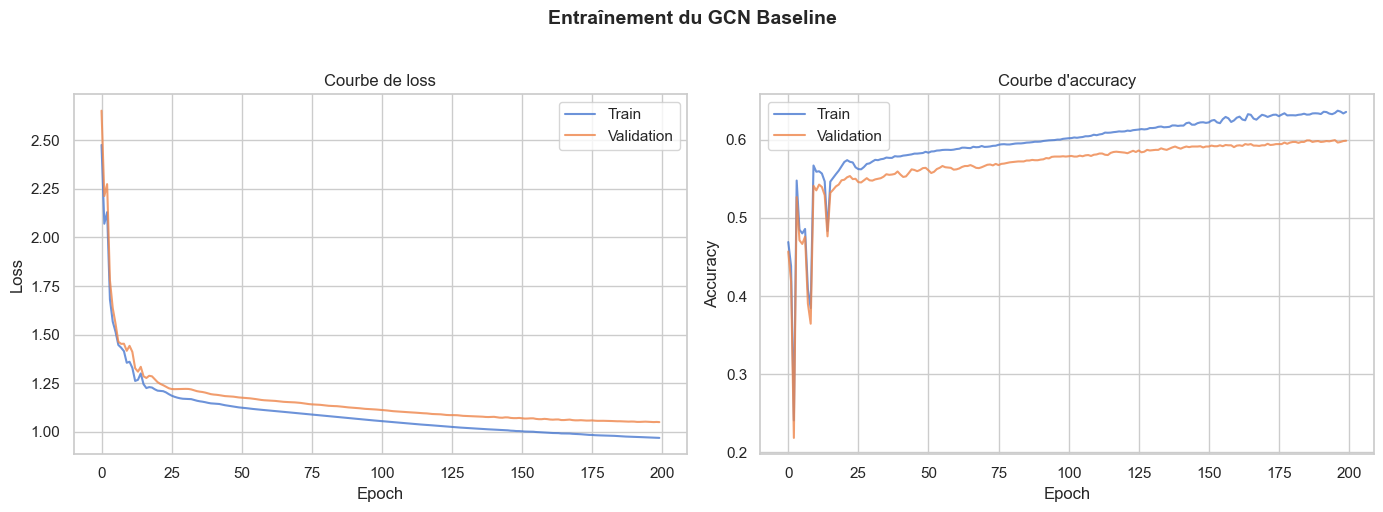

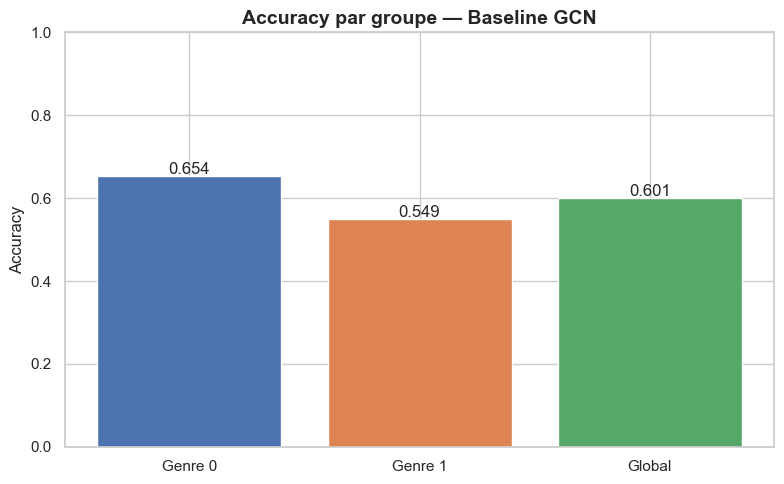


Accuracy Genre 0 : 0.6542
Accuracy Genre 1 : 0.5495
Écart             : 0.1047


In [7]:
# === ÉVALUATION : PERFORMANCE + FAIRNESS ===

# Métriques sur le test set
baseline_results = evaluate_model(model, data, test_mask, data.sens)
baseline_results["model"] = "Baseline GCN"
all_results.append(baseline_results)

print("=" * 55)
print("     RÉSULTATS BASELINE — TEST SET")
print("=" * 55)
results_df = pd.DataFrame([baseline_results])
print(results_df[["model", "accuracy", "f1_macro", "dp_gap", "eopp_gap", "eo_gap"]].to_string(index=False))

dp = baseline_results["dp_gap"]
print(f"\nDP gap = {dp:.4f} → {'FAIR (< 0.05)' if dp < 0.05 else 'BIAISÉ (≥ 0.05)'}")

# --- Visualisations ---

# 1. Courbes de loss et accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label="Train", alpha=0.8)
axes[0].plot(val_losses, label="Validation", alpha=0.8)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Courbe de loss")
axes[0].legend()

axes[1].plot(train_accs, label="Train", alpha=0.8)
axes[1].plot(val_accs, label="Validation", alpha=0.8)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Courbe d'accuracy")
axes[1].legend()

fig.suptitle("Entraînement du GCN Baseline", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 2. Accuracy par groupe
model.eval()
with torch.no_grad():
    test_preds = model(data.x, data.edge_index)[test_mask].argmax(dim=-1)

y_test = data.y[test_mask]
sens_test = data.sens[test_mask]

acc_g0 = (test_preds[sens_test == 0] == y_test[sens_test == 0]).float().mean().item()
acc_g1 = (test_preds[sens_test == 1] == y_test[sens_test == 1]).float().mean().item()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["Genre 0", "Genre 1", "Global"],
              [acc_g0, acc_g1, baseline_results["accuracy"]],
              color=["#4C72B0", "#DD8452", "#55A868"], edgecolor="white")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy par groupe — Baseline GCN", fontsize=14, fontweight="bold")
for bar, v in zip(bars, [acc_g0, acc_g1, baseline_results["accuracy"]]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{v:.3f}", ha="center", fontsize=12)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

print(f"\nAccuracy Genre 0 : {acc_g0:.4f}")
print(f"Accuracy Genre 1 : {acc_g1:.4f}")
print(f"Écart             : {abs(acc_g0 - acc_g1):.4f}")

### Observations Acte 1

- TODO: Commenter les résultats baseline
- TODO: Le biais est-il significatif ?
- TODO: Implications pour l'acte suivant

## 2. Acte 2 — Diagnostic XAI

**Objectif** : Comprendre d'où vient le biais via l'interprétabilité.
**Méthode** : GNNExplainer (local) + GNNShap (global).
**Réf.** : Ying et al. (NeurIPS 2019), Mastropietro et al. (WWW 2024).

Genre 0 — correct: 3 nœuds
Genre 0 — incorrect: 3 nœuds
Genre 1 — correct: 3 nœuds
Genre 1 — incorrect: 3 nœuds
Total : 12 nœuds à expliquer
  [1/12] Nœud 26268 — sous-graphe: 698 nœuds, 14918 arêtes — 1.6s
  [2/12] Nœud 47494 — sous-graphe: 219 nœuds, 1958 arêtes — 2.3s
  [3/12] Nœud 9943 — sous-graphe: 602 nœuds, 4642 arêtes — 3.3s
  [4/12] Nœud 17058 — sous-graphe: 471 nœuds, 3194 arêtes — 4.1s
  [5/12] Nœud 20301 — sous-graphe: 441 nœuds, 1692 arêtes — 4.9s
  [6/12] Nœud 31966 — sous-graphe: 107 nœuds, 406 arêtes — 5.5s
  [7/12] Nœud 54354 — sous-graphe: 222 nœuds, 1188 arêtes — 6.1s
  [8/12] Nœud 48282 — sous-graphe: 75 nœuds, 208 arêtes — 6.5s
  [9/12] Nœud 50771 — sous-graphe: 60 nœuds, 592 arêtes — 7.0s
  [10/12] Nœud 10379 — sous-graphe: 4411 nœuds, 154920 arêtes — 18.5s
  [11/12] Nœud 27607 — sous-graphe: 217 nœuds, 1362 arêtes — 19.1s
  [12/12] Nœud 15568 — sous-graphe: 337 nœuds, 5346 arêtes — 20.0s
GNNExplainer terminé en 20.0s
>>> Genre : rang 35/277 dans l'importance des

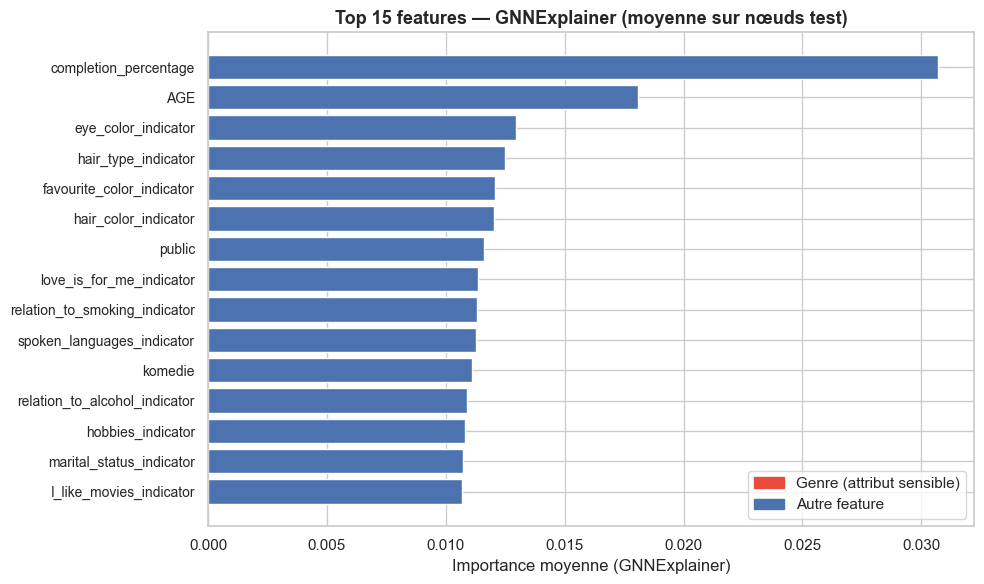

Top 10 features les plus importantes :


,feature,importance
1,completion_percentage,0.030683
4,AGE,0.018081
69,eye_color_indicator,0.012961
77,hair_type_indicator,0.012495
89,favourite_color_indicator,0.012088
73,hair_color_indicator,0.012011
0,public,0.011615
117,love_is_for_me_indicator,0.011368
100,relation_to_smoking_indicator,0.011324
5,spoken_languages_indicator,0.011268


In [8]:
# === GNNEXPLAINER — EXPLICATION LOCALE ===
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.utils import k_hop_subgraph
import time

explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=100, lr=0.01),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type=None,
    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw",
    ),
)

# --- Sélection stratégique de nœuds ---
model.eval()
with torch.no_grad():
    test_logits = model(data.x, data.edge_index)
    test_preds = test_logits[test_mask].argmax(dim=-1)

test_idx = test_mask.nonzero(as_tuple=True)[0]
y_test = data.y[test_mask]
sens_test = data.sens[test_mask]
correct = (test_preds == y_test)

def select_nodes(group_val: int, is_correct: bool, n: int = 3) -> list:
    """Sélectionne n nœuds du test set par groupe et statut de classification."""
    mask_group = sens_test == group_val
    mask_status = correct if is_correct else ~correct
    candidates = test_idx[(mask_group & mask_status).nonzero(as_tuple=True)[0]]
    if len(candidates) == 0:
        return []
    set_seed(42)
    perm = torch.randperm(len(candidates))[:n]
    return candidates[perm].tolist()

nodes_to_explain = {
    "Genre 0 — correct": select_nodes(0, True),
    "Genre 0 — incorrect": select_nodes(0, False),
    "Genre 1 — correct": select_nodes(1, True),
    "Genre 1 — incorrect": select_nodes(1, False),
}

total_nodes = sum(len(v) for v in nodes_to_explain.values())
for cat, nodes in nodes_to_explain.items():
    print(f"{cat}: {len(nodes)} nœuds")
print(f"Total : {total_nodes} nœuds à expliquer")

# --- Explication via sous-graphe local 2-hop (beaucoup plus rapide) ---
all_node_masks = []
all_nodes_flat = []
t0 = time.time()
count = 0

for cat, nodes in nodes_to_explain.items():
    for node_idx in nodes:
        count += 1
        # Extraire le sous-graphe 2-hop (seul le voisinage du nœud compte pour un GCN 2 couches)
        subset, sub_edge_index, mapping, _ = k_hop_subgraph(
            node_idx, num_hops=2, edge_index=data.edge_index,
            relabel_nodes=True, num_nodes=data.num_nodes
        )
        sub_x = data.x[subset]
        local_idx = mapping.item()

        explanation = explainer(sub_x, sub_edge_index, index=local_idx)
        feat_mask = explanation.node_mask.detach().cpu()
        if feat_mask.dim() > 1:
            feat_mask = feat_mask.mean(dim=0)
        feat_mask = feat_mask / (feat_mask.sum() + 1e-8)
        all_node_masks.append(feat_mask)
        all_nodes_flat.append({
            "node_idx": node_idx,
            "genre": data.sens[node_idx].item(),
            "correct": (data.y[node_idx] == test_logits[node_idx].argmax().item()),
        })
        elapsed = time.time() - t0
        print(f"  [{count}/{total_nodes}] Nœud {node_idx} — "
              f"sous-graphe: {len(subset)} nœuds, {sub_edge_index.shape[1]} arêtes — "
              f"{elapsed:.1f}s")

print(f"GNNExplainer terminé en {time.time()-t0:.1f}s")

# --- Importance moyenne des features ---
mean_importance = torch.stack(all_node_masks).mean(dim=0).numpy()
feature_names = data.feature_names

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": mean_importance
}).sort_values("importance", ascending=False)

# Position du genre
gender_rank = importance_df.reset_index(drop=True)
gender_row = gender_rank[gender_rank["feature"] == "gender"]
if len(gender_row) > 0:
    gender_pos = gender_row.index[0] + 1
    print(f">>> Genre : rang {gender_pos}/{len(feature_names)} dans l'importance des features")
else:
    print(">>> Feature 'gender' non trouvée dans les noms de colonnes")

# --- Visualisation : top-15 features ---
top_k = 15
top = importance_df.head(top_k)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#E74C3C" if f == "gender" else "#4C72B0" for f in top["feature"]]
ax.barh(range(top_k), top["importance"].values, color=colors, edgecolor="white")
ax.set_yticks(range(top_k))
ax.set_yticklabels(top["feature"].values, fontsize=10)
ax.set_xlabel("Importance moyenne (GNNExplainer)")
ax.set_title("Top 15 features — GNNExplainer (moyenne sur nœuds test)",
             fontsize=13, fontweight="bold")
ax.invert_yaxis()

import matplotlib.patches as mpatches
legend_items = [mpatches.Patch(color="#E74C3C", label="Genre (attribut sensible)"),
                mpatches.Patch(color="#4C72B0", label="Autre feature")]
ax.legend(handles=legend_items, loc="lower right")
plt.tight_layout()
plt.show()

print(f"Top 10 features les plus importantes :")
display(importance_df.head(10))


Calcul GNNShap sur 50 nœuds par groupe...
  Genre 0... OK
  Genre 1... OK


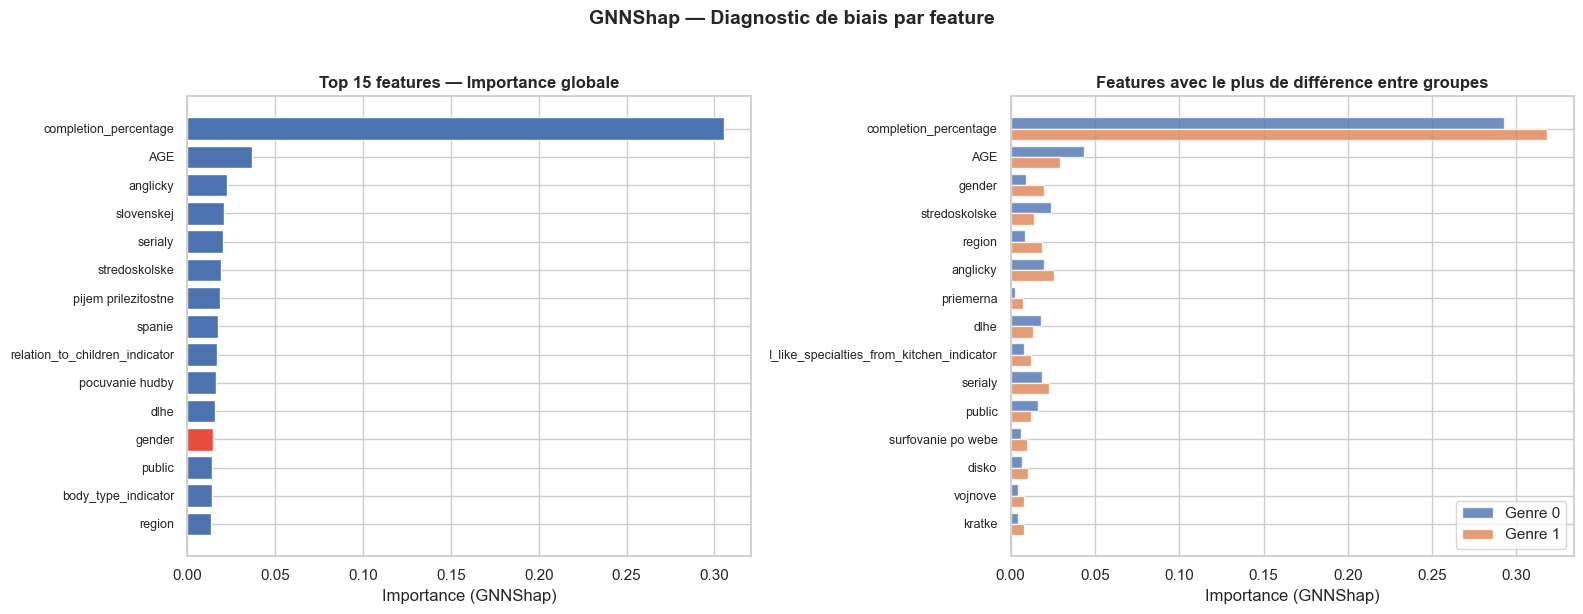


>>> GNNShap — Genre : rang 12/277

>>> Top 5 proxies du genre (plus grande différence d'importance entre groupes) :


,feature,importance_g0,importance_g1,diff
1,completion_percentage,0.2925,0.3182,0.0257
4,AGE,0.0438,0.0294,0.0143
2,gender,0.0091,0.0198,0.0107
85,stredoskolske,0.0242,0.0138,0.0104
3,region,0.0086,0.0185,0.0099


In [9]:
# === GNNSHAP SIMPLIFIÉ — EXPLICATION GLOBALE ===

class SimpleGNNShap:
    """Shapley values simplifiées par ablation de features.

    Pour chaque feature, on la met à zéro et on mesure le changement
    de prédiction. C'est une approximation du marginal contribution
    (Shapley value d'ordre 1).
    Réf. : Mastropietro et al. (WWW 2024), version simplifiée.
    """
    def __init__(self, model, data):
        self.model = model
        self.data = data
        self.model.eval()

    @torch.no_grad()
    def explain_nodes(self, node_indices: list) -> torch.Tensor:
        """Calcule l'importance de chaque feature pour un ensemble de nœuds.

        Returns:
            importance: Tensor [num_features] — importance moyenne.
        """
        x, edge_index = self.data.x, self.data.edge_index
        num_features = x.shape[1]

        # Prédiction de référence (toutes features)
        base_probs = F.softmax(self.model(x, edge_index), dim=-1)

        importances = torch.zeros(num_features)

        for f_idx in range(num_features):
            # Masquer la feature f_idx (mettre à 0)
            x_masked = x.clone()
            x_masked[:, f_idx] = 0.0
            masked_probs = F.softmax(self.model(x_masked, edge_index), dim=-1)

            # Changement de prédiction pour les nœuds cibles
            for node_idx in node_indices:
                pred_class = base_probs[node_idx].argmax().item()
                delta = base_probs[node_idx, pred_class] - masked_probs[node_idx, pred_class]
                importances[f_idx] += delta.item()

        importances /= len(node_indices)
        return importances.abs()


# --- Calcul par groupe ---
shap_explainer = SimpleGNNShap(model, data)

set_seed(42)
n_sample = 50

# Échantillonner des nœuds test par groupe
g0_test = test_idx[sens_test == 0]
g1_test = test_idx[sens_test == 1]
g0_sample = g0_test[torch.randperm(len(g0_test))[:n_sample]].tolist()
g1_sample = g1_test[torch.randperm(len(g1_test))[:n_sample]].tolist()

print(f"Calcul GNNShap sur {n_sample} nœuds par groupe...")
print("  Genre 0...", end=" ")
shap_g0 = shap_explainer.explain_nodes(g0_sample)
print("OK")
print("  Genre 1...", end=" ")
shap_g1 = shap_explainer.explain_nodes(g1_sample)
print("OK")

# Importance globale (moyenne des deux groupes)
shap_global = (shap_g0 + shap_g1) / 2

# --- Visualisation 1 : Top features globales ---
shap_df = pd.DataFrame({
    "feature": feature_names,
    "importance_g0": shap_g0.numpy(),
    "importance_g1": shap_g1.numpy(),
    "importance_global": shap_global.numpy(),
    "diff": (shap_g0 - shap_g1).abs().numpy(),
}).sort_values("importance_global", ascending=False)

top_shap = shap_df.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Importance globale
colors = ["#E74C3C" if f == "gender" else "#4C72B0" for f in top_shap["feature"]]
axes[0].barh(range(len(top_shap)), top_shap["importance_global"].values,
             color=colors, edgecolor="white")
axes[0].set_yticks(range(len(top_shap)))
axes[0].set_yticklabels(top_shap["feature"].values, fontsize=9)
axes[0].set_xlabel("Importance (GNNShap)")
axes[0].set_title("Top 15 features — Importance globale", fontweight="bold")
axes[0].invert_yaxis()

# Comparaison entre groupes
top_diff = shap_df.sort_values("diff", ascending=False).head(15)
y_pos = range(len(top_diff))
axes[1].barh(y_pos, top_diff["importance_g0"].values, height=0.4,
             label="Genre 0", color="#4C72B0", alpha=0.8)
axes[1].barh([y + 0.4 for y in y_pos], top_diff["importance_g1"].values, height=0.4,
             label="Genre 1", color="#DD8452", alpha=0.8)
axes[1].set_yticks([y + 0.2 for y in y_pos])
axes[1].set_yticklabels(top_diff["feature"].values, fontsize=9)
axes[1].set_xlabel("Importance (GNNShap)")
axes[1].set_title("Features avec le plus de différence entre groupes", fontweight="bold")
axes[1].invert_yaxis()
axes[1].legend()

fig.suptitle("GNNShap — Diagnostic de biais par feature", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Position du genre
gender_shap_rank = shap_df.reset_index(drop=True)
gender_shap_row = gender_shap_rank[gender_shap_rank["feature"] == "gender"]
if len(gender_shap_row) > 0:
    rank = gender_shap_row.index[0] + 1
    print(f"\n>>> GNNShap — Genre : rang {rank}/{len(feature_names)}")

# Top 5 proxies du genre (features avec la plus grande différence entre groupes)
proxies = shap_df.sort_values("diff", ascending=False).head(5)
print("\n>>> Top 5 proxies du genre (plus grande différence d'importance entre groupes) :")
display(proxies[["feature", "importance_g0", "importance_g1", "diff"]].round(4))

Calcul Fidelity pour GNNExplainer...
Calcul Fidelity pour GNNShap...

=== Évaluation XAI — Fidelity+/- ===


,Méthode,K,fidelity+,fidelity-
0,GNNExplainer,5,0.7862,0.2770
1,GNNExplainer,10,0.7823,0.2685
2,GNNExplainer,20,0.7935,0.2150
3,GNNExplainer,50,0.8492,0.2026
4,GNNShap,5,0.7967,0.3664
5,GNNShap,10,0.8254,0.3404
6,GNNShap,20,0.8309,0.3076
7,GNNShap,50,0.8545,0.4158


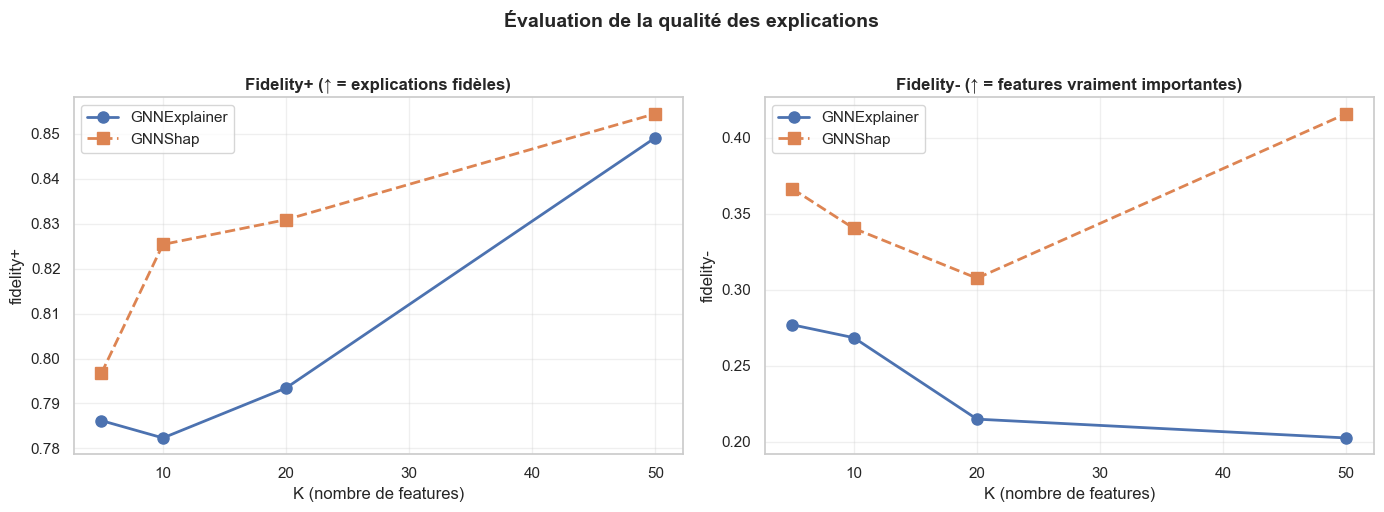


Fidelity+ élevé → les top-K features suffisent pour reproduire la prédiction
Fidelity- élevé → retirer les top-K features change significativement la prédiction


In [11]:
# === ÉVALUATION XAI — FIDELITY+/- ===

@torch.no_grad()
def compute_fidelity(model, data, node_indices: list,
                     feature_importance: np.ndarray,
                     top_k_values: list = [5, 10, 20, 50]) -> dict:
    """Calcule Fidelity+ et Fidelity- pour différentes valeurs de K.

    Fidelity+ : garder seulement les top-K features → prédiction stable ?
    Fidelity- : retirer les top-K features → prédiction change ?

    Réf. : cours Interprétabilité d'Alché-Buc (p.93-97)
    """
    model.eval()
    x, edge_index = data.x, data.edge_index

    # Prédiction de référence
    base_probs = F.softmax(model(x, edge_index), dim=-1)

    # Ranking des features par importance décroissante
    ranked_features = np.argsort(feature_importance)[::-1].copy()

    results = []
    for k in top_k_values:
        if k > len(ranked_features):
            continue
        top_k_idx = ranked_features[:k]
        other_idx = ranked_features[k:]

        # Fidelity+ : garder seulement les top-K, mettre le reste à 0
        x_plus = x.clone()
        x_plus[:, other_idx] = 0.0
        probs_plus = F.softmax(model(x_plus, edge_index), dim=-1)

        # Fidelity- : retirer les top-K, garder le reste
        x_minus = x.clone()
        x_minus[:, top_k_idx] = 0.0
        probs_minus = F.softmax(model(x_minus, edge_index), dim=-1)

        fid_plus_scores, fid_minus_scores = [], []
        for node_idx in node_indices:
            pred_class = base_probs[node_idx].argmax().item()

            # Fidelity+ : 1 - |p_orig - p_masked| → plus c'est haut, mieux c'est
            fid_p = 1.0 - abs(base_probs[node_idx, pred_class].item() -
                              probs_plus[node_idx, pred_class].item())
            fid_plus_scores.append(fid_p)

            # Fidelity- : |p_orig - p_masked| → plus c'est haut, mieux c'est
            fid_m = abs(base_probs[node_idx, pred_class].item() -
                        probs_minus[node_idx, pred_class].item())
            fid_minus_scores.append(fid_m)

        results.append({
            "K": k,
            "fidelity+": np.mean(fid_plus_scores),
            "fidelity-": np.mean(fid_minus_scores),
        })

    return results


# --- Calcul sur les nœuds test ---
set_seed(42)
eval_nodes = test_idx[torch.randperm(len(test_idx))[:100]].tolist()

# Fidelity pour GNNExplainer
print("Calcul Fidelity pour GNNExplainer...")
fid_gnnexp = compute_fidelity(model, data, eval_nodes, mean_importance,
                               top_k_values=[5, 10, 20, 50])

# Fidelity pour GNNShap
print("Calcul Fidelity pour GNNShap...")
fid_shap = compute_fidelity(model, data, eval_nodes, shap_global.numpy(),
                             top_k_values=[5, 10, 20, 50])

# --- Tableau récapitulatif ---
fid_rows = []
for r in fid_gnnexp:
    fid_rows.append({"Méthode": "GNNExplainer", **r})
for r in fid_shap:
    fid_rows.append({"Méthode": "GNNShap", **r})

fid_df = pd.DataFrame(fid_rows)
print("\n=== Évaluation XAI — Fidelity+/- ===")
display(fid_df.round(4))

# --- Visualisation ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, title in [
    (axes[0], "fidelity+", "Fidelity+ (↑ = explications fidèles)"),
    (axes[1], "fidelity-", "Fidelity- (↑ = features vraiment importantes)"),
]:
    for method, marker, color in [
        ("GNNExplainer", "o-", "#4C72B0"),
        ("GNNShap", "s--", "#DD8452"),
    ]:
        subset = fid_df[fid_df["Méthode"] == method]
        ax.plot(subset["K"], subset[metric], marker, color=color,
                label=method, linewidth=2, markersize=8)
    ax.set_xlabel("K (nombre de features)")
    ax.set_ylabel(metric)
    ax.set_title(title, fontweight="bold")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle("Évaluation de la qualité des explications", fontsize=14,
             fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("\nFidelity+ élevé → les top-K features suffisent pour reproduire la prédiction")
print("Fidelity- élevé → retirer les top-K features change significativement la prédiction")

### Observations Acte 2

- TODO: Le genre est-il dans le top features ?
- TODO: Quels proxies du genre sont détectés ?
- TODO: Implications pour les corrections

## 3. Acte 3 — Correction Fairness

**Objectif** : Appliquer des méthodes de mitigation ciblées par le diagnostic.
**Méthode** : Reweighting (pré), régularisation DP (in), seuils (post).
**Réf.** : Cours Laclau (Mitigation), Chouldechova (2017).

In [ ]:
# === REWEIGHTING ===
# TODO: Implémenter

In [ ]:
# === RÉGULARISATION DP (sweep λ) ===
# TODO: Implémenter

In [ ]:
# === COURBE DE PARETO ===
# TODO: Implémenter

In [ ]:
# === TABLEAU COMPARATIF ===
# TODO: Implémenter

### Observations Acte 3

- TODO: Quel λ offre le meilleur compromis ?
- TODO: Le seuil fair (DP < 0.05) est-il atteint ?
- TODO: Coût en accuracy ?

## 4. Acte 4 — Validation & Incertitude

**Objectif** : Vérifier la robustesse des corrections et quantifier l'incertitude.
**Méthode** : MC Dropout (T=30), perturbations (arêtes + features).
**Réf.** : Gal & Ghahramani (ICML 2016), cours Franchi (Uncertainty).

In [ ]:
# === MC DROPOUT ===
# TODO: Implémenter

In [ ]:
# === PERTURBATIONS (arêtes + features) ===
# TODO: Implémenter

In [ ]:
# === ECE + RELIABILITY DIAGRAM ===
# TODO: Implémenter

In [ ]:
# === COMPROMIS 3D : PERF ↔ FAIRNESS ↔ ROBUSTESSE ===
# TODO: Implémenter

### Observations Acte 4

- TODO: Le modèle fair est-il plus/moins robuste ?
- TODO: L'incertitude est-elle différente par groupe ?
- TODO: Discussion du compromis 3D

## 5. Conclusion & Résumé des Résultats

TODO: Résumé final avec tableau récapitulatif de tous les modèles et métriques.